# 02 · Preprocesamiento y variables por corte k
TA Aprendizaje de Máquina, grupo 5. Entregable 2.

**Objetivo.** Limpiar Times y Monitoring, unirlos y construir el dataset vuelta × corte k (k ∈ {4, 6, 9, 12, 15}) con los cuatro grupos de variables, sin información posterior al corte.

**Entradas:** `data/raw/Times.csv`, `data/raw/Monitoring.csv`.
**Salidas:** `data/processed/corte_k{k}.pkl` (con regla de 60 min) y `corte_k{k}_sin_regla.pkl`; tablas y figuras con prefijo `02_`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.datos import (COL_DIF, PUNTOS, UMBRAL_EXTREMO, LAP_FUERA_DE_OPERACION,
                       aplicar_regla_extremos, cargar_monitoring, cargar_times)
from src.variables import (CORTES, GRUPOS, NOMBRE_GRUPO, columnas_modelo, construir_corte, indexar_gps,
                           pasadas_por_punto)
from src.particion import asignar_particion
from src import graficos

SEMILLA = 42
DIR_RAW = RAIZ / "data" / "raw"
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
for d in (DIR_PROC, DIR_FIG, DIR_TAB):
    d.mkdir(parents=True, exist_ok=True)
graficos.estilo()
pd.set_option("display.max_columns", 40)

## 1. Carga
Times se convierte a una fila por vuelta con 18 columnas de hora programada (`prog_j`), hora real (`real_j`, NaN si `00:00:00`) y diferencia (`dif_j`, NaN si `-`). En Monitoring se descartan los puntos con `lap` = 0 (fuera de operación) y las filas repetidas sin contar el `id`.

In [2]:
vueltas = cargar_times(DIR_RAW / "Times.csv")
mon_bruto = pd.read_csv(DIR_RAW / "Monitoring.csv", usecols=["date", "time", "lap", "latitude", "longitude",
                                                            "speed", "bearing", "vehicle_id_id"])
gps = cargar_monitoring(DIR_RAW / "Monitoring.csv")

resumen_carga = pd.Series({
    "Times: vueltas": len(vueltas),
    "Times: vehículos": vueltas["vehiculo"].nunique(),
    "Times: días": vueltas["fecha"].nunique(),
    "Monitoring: filas": len(mon_bruto),
    "Monitoring: lap = 0": int((mon_bruto["lap"] == LAP_FUERA_DE_OPERACION).sum()),
    "Monitoring: repetidas sin id": int(mon_bruto.duplicated().sum()),
    "Monitoring: filas usadas": len(gps),
})
del mon_bruto
resumen_carga

Times: vueltas                     4707
Times: vehículos                     45
Times: días                          27
Monitoring: filas               1630431
Monitoring: lap = 0               47921
Monitoring: repetidas sin id       6690
Monitoring: filas usadas        1575820
dtype: int64

## 2. Análisis exploratorio
Faltantes y valores extremos por punto de control, distribución del objetivo (punto 18) y relación del atraso de cada punto con el del punto 18.

In [3]:
dif = vueltas[COL_DIF].to_numpy()
extremo = np.abs(dif) > UMBRAL_EXTREMO
dif_limpio = np.where(extremo, np.nan, dif)
y18 = dif_limpio[:, PUNTOS - 1]

por_punto = pd.DataFrame({
    "punto": range(1, PUNTOS + 1),
    "pct_faltante": 100 * np.isnan(dif).mean(axis=0),
    "n_extremos": extremo.sum(axis=0),
    "media": np.nanmean(dif_limpio, axis=0),
    "desv_est": np.nanstd(dif_limpio, axis=0),
    "corr_con_18": [pd.Series(dif_limpio[:, j]).corr(pd.Series(y18)) for j in range(PUNTOS)],
}).round(3)
por_punto.to_csv(DIR_TAB / "02_eda_por_punto.csv", index=False)
por_punto

,punto,pct_faltante,n_extremos,media,desv_est,corr_con_18
0,1,6.650,1,-0.680,1.840,-0.070
1,2,5.821,2,-1.346,1.856,-0.077
2,3,12.152,0,-1.032,1.218,0.034
3,4,6.034,0,-0.118,1.514,0.392
4,5,6.650,0,-0.278,2.425,0.539
5,6,6.926,0,0.938,4.133,0.722
6,7,6.607,0,0.323,4.083,0.723
7,8,6.289,0,1.225,4.299,0.729
8,9,6.522,0,0.760,4.110,0.720
9,10,6.628,1,0.270,4.186,0.761


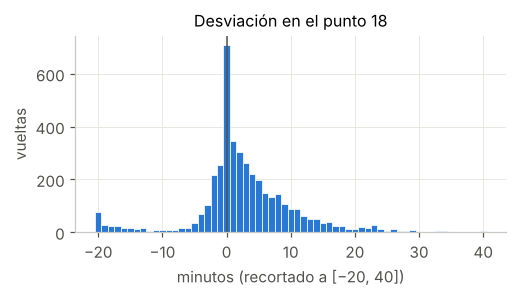

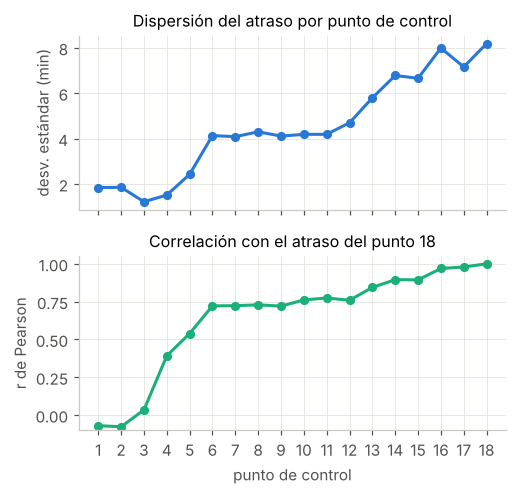

Punto 18 sin extremos: n=4146, mediana=2.0, media=2.72, p05=-13, p95=16, p99=26


In [4]:
v = y18[~np.isnan(y18)]
fig, ax = plt.subplots(figsize=(4.8, 2.8))
ax.hist(np.clip(v, -20, 40), bins=np.arange(-20.5, 41.5, 1), color=graficos.PALETA[0], edgecolor="white", linewidth=0.5)
ax.axvline(0, color=graficos.TEXTO_SEC, linewidth=1)
ax.set(title="Desviación en el punto 18", xlabel="minutos (recortado a [−20, 40])", ylabel="vueltas")
graficos.guardar(fig, DIR_FIG / "02_eda_punto18.png")

fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.6), sharex=True)
ejes[0].plot(por_punto["punto"], por_punto["desv_est"], marker="o", color=graficos.PALETA[0])
ejes[0].set(title="Dispersión del atraso por punto de control", ylabel="desv. estándar (min)")
ejes[1].plot(por_punto["punto"], por_punto["corr_con_18"], marker="o", color=graficos.PALETA[2])
ejes[1].set(title="Correlación con el atraso del punto 18", xlabel="punto de control", ylabel="r de Pearson",
            ylim=(-0.1, 1.05), xticks=range(1, PUNTOS + 1))
graficos.guardar(fig, DIR_FIG / "02_eda_por_punto.png")
print(f"Punto 18 sin extremos: n={len(v)}, mediana={np.median(v):.1f}, media={v.mean():.2f}, "
      f"p05={np.percentile(v, 5):.0f}, p95={np.percentile(v, 95):.0f}, p99={np.percentile(v, 99):.0f}")

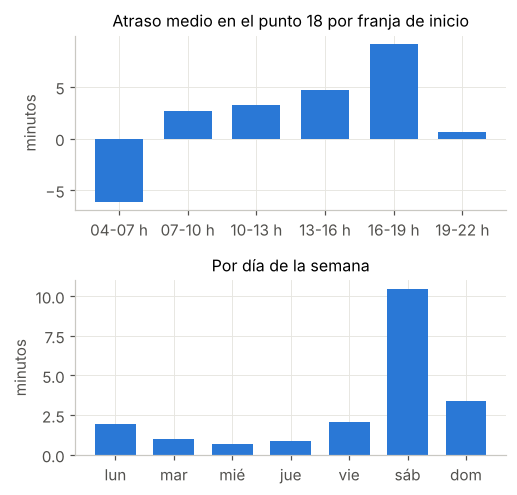

count   mean  median
franja 04-07 h    739  -6.16    -2.0
       07-10 h    875   2.66     1.0
       10-13 h    856   3.23     1.0
       13-16 h    840   4.72     3.0
       16-19 h    727   9.19     8.0
       19-22 h    109   0.61    -1.0
dia    lun        613   1.94     2.0
       mar        657   1.00     1.0
       mié        676   0.66     0.0
       jue        670   0.90     1.0
       vie        663   2.05     2.0
       sáb        576  10.46    11.0
       dom        291   3.36     1.0

In [5]:
eda = pd.DataFrame({
    "y": y18,
    "dia": vueltas["fecha"].dt.dayofweek,
    "hora": vueltas["prog_1"] / 60,
})
eda["franja"] = pd.cut(eda["hora"], bins=[4, 7, 10, 13, 16, 19, 22], right=False,
                       labels=["04-07 h", "07-10 h", "10-13 h", "13-16 h", "16-19 h", "19-22 h"]).astype(str)
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
eda["dia_nombre"] = eda["dia"].map(dict(enumerate(DIAS)))
por_franja = eda.groupby("franja")["y"].agg(["count", "mean", "median"]).round(2)
por_dia = eda.groupby("dia")["y"].agg(["count", "mean", "median"]).round(2).set_index(pd.Index(DIAS, name="dia"))
pd.concat({"franja": por_franja, "dia": por_dia}).to_csv(DIR_TAB / "02_eda_franja_dia.csv")

fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.6))
ejes[0].bar(por_franja.index, por_franja["mean"], color=graficos.PALETA[0], width=0.7)
ejes[0].set(title="Atraso medio en el punto 18 por franja de inicio", ylabel="minutos")
ejes[1].bar(por_dia.index, por_dia["mean"], color=graficos.PALETA[0], width=0.7)
ejes[1].set(title="Por día de la semana", ylabel="minutos")
graficos.guardar(fig, DIR_FIG / "02_eda_franja_dia.png")
pd.concat({"franja": por_franja, "dia": por_dia})

## 3. Filtros
El objetivo es `difference_time` del punto 18; se excluyen las vueltas sin ese valor. Con la regla provisional, todo punto con |valor| > 60 min se trata como error de registro: si es el punto 18, la vuelta sale del dataset; si es un punto intermedio, pasa a faltante.

In [6]:
sin_18 = vueltas["dif_18"].isna()
y_extremo = vueltas["dif_18"].abs() > UMBRAL_EXTREMO
filtros = pd.Series({
    "Vueltas en Times": len(vueltas),
    "Sin punto 18 válido": int(sin_18.sum()),
    "Con punto 18 válido (sin regla)": int((~sin_18).sum()),
    "|punto 18| > 60 min": int(y_extremo.sum()),
    "Con regla de 60 min": int((~sin_18 & ~y_extremo).sum()),
    "Puntos intermedios > 60 min en vueltas que quedan": int(extremo[(~sin_18 & ~y_extremo).to_numpy(), :PUNTOS - 1].sum()),
    "Horario no creciente (se mantienen con indicador)": int((np.diff(vueltas.filter(like="prog_").to_numpy(), axis=1) < 0).any(axis=1).sum()),
}, name="vueltas")
filtros.to_csv(DIR_TAB / "02_filtros.csv")
filtros

Vueltas en Times                                     4707
Sin punto 18 válido                                   515
Con punto 18 válido (sin regla)                      4192
|punto 18| > 60 min                                    46
Con regla de 60 min                                  4146
Puntos intermedios > 60 min en vueltas que quedan       1
Horario no creciente (se mantienen con indicador)     148
Name: vueltas, dtype: int64

## 4. Dataset vuelta × corte k
El instante de predicción es la hora real de paso por el punto k (la programada si no se registró). Variables por grupo (prefijo):

- `hor_`: hora de inicio (seno, coseno y hora), día de la semana, minutos programados restantes y totales, duración programada de cada tramo restante, indicador de horario no creciente.
- `atr_`: atraso en los puntos 1 a k con indicador de faltante, último valor (entero y continuo en segundos/60), distancia al último registro, media de los últimos tres, máximo, mínimo, pendiente y número de faltantes.
- `ctx_`: vehículo, número de vuelta del día, atraso final de la vuelta anterior solo si terminó antes del corte, y atraso medio de otros vehículos en los 30 min previos al corte (con su número de registros).
- `gps_`: puntos GPS de la vuelta hasta el corte, velocidad media, proporción detenida (< 2 km/h) y velocidad media de los últimos 10 min.

In [7]:
indice_gps = indexar_gps(gps)
filas = []
for regla in (True, False):
    base = aplicar_regla_extremos(vueltas) if regla else vueltas
    pasadas = pasadas_por_punto(base)
    for k in CORTES:
        x = asignar_particion(construir_corte(base, k, indice_gps, pasadas))
        sufijo = "" if regla else "_sin_regla"
        x.to_pickle(DIR_PROC / f"corte_k{k}{sufijo}.pkl")
        filas.append({"regla_60": regla, "k": k, "observaciones": len(x),
                      "train": int((x["conjunto"] == "train").sum()), "test": int((x["conjunto"] == "test").sum()),
                      "variables": len(columnas_modelo(x)),
                      **{f"vars_{g}": len(columnas_modelo(x, (g,))) for g in GRUPOS}})
filas_por_corte = pd.DataFrame(filas)
filas_por_corte.to_csv(DIR_TAB / "02_filas_por_corte.csv", index=False)
filas_por_corte

,regla_60,k,observaciones,train,test,variables,vars_hor,vars_atr,vars_ctx,vars_gps
0,True,4,4146,3085,1061,47,21,16,6,4
1,True,6,4146,3085,1061,49,19,20,6,4
2,True,9,4146,3085,1061,52,16,26,6,4
3,True,12,4146,3085,1061,55,13,32,6,4
4,True,15,4146,3085,1061,58,10,38,6,4
5,False,4,4192,3120,1072,47,21,16,6,4
6,False,6,4192,3120,1072,49,19,20,6,4
7,False,9,4192,3120,1072,52,16,26,6,4
8,False,12,4192,3120,1072,55,13,32,6,4
9,False,15,4192,3120,1072,58,10,38,6,4


## 5. Partición temporal y pliegues
Entrenamiento: 6–25 ene (20 días). Prueba: 26 ene–1 feb (7 días), usada una sola vez. Pliegues de ventana creciente: los 8 primeros días siempre entrenan y cada pliegue valida un bloque de 3 días consecutivos con todos los días anteriores.

In [8]:
x9 = pd.read_pickle(DIR_PROC / "corte_k9.pkl")
tr = x9[x9["conjunto"] == "train"]
pl = []
for f in range(4):
    ent, val = tr[tr["bloque"] < f], tr[tr["bloque"] == f]
    pl.append({"pliegue": f + 1,
               "entrena": f"{ent['fecha'].min():%d/%m}–{ent['fecha'].max():%d/%m}", "n_entrena": len(ent),
               "valida": f"{val['fecha'].min():%d/%m}–{val['fecha'].max():%d/%m}", "n_valida": len(val)})
pliegues_tab = pd.DataFrame(pl)
pliegues_tab.to_csv(DIR_TAB / "02_pliegues.csv", index=False)
pliegues_tab

,pliegue,entrena,n_entrena,valida,n_valida
0,1,06/01–13/01,1216,14/01–16/01,498
1,2,06/01–16/01,1714,17/01–19/01,401
2,3,06/01–19/01,2115,20/01–22/01,472
3,4,06/01–22/01,2587,23/01–25/01,498


In [9]:
cols = columnas_modelo(x9)
variables_k9 = pd.DataFrame({
    "variable": cols,
    "grupo": [NOMBRE_GRUPO[c.split("_")[0]] for c in cols],
    "pct_faltante": [round(100 * x9[c].isna().mean(), 2) for c in cols],
})
variables_k9.to_csv(DIR_TAB / "02_variables_k9.csv", index=False)
variables_k9.groupby("grupo", sort=False).agg(n=("variable", "size"), pct_faltante_max=("pct_faltante", "max"))

,n,pct_faltante_max
grupo,,
Horario,16,0.00
Atraso observado,26,8.01
Vehículo y contexto,6,29.57
GPS,4,1.59


## 6. Conclusiones
- Times tiene 4.707 vueltas; 515 (10,9 %) no tienen punto 18 válido y 46 superan 60 min en el punto 18. Con la regla quedan 4.146 observaciones por corte (3.085 de entrenamiento y 1.061 de prueba); sin ella, 4.192.
- De Monitoring se descartan 47.921 puntos fuera de operación (`lap` = 0) y 6.690 filas repetidas: quedan 1.575.820 puntos GPS.
- Objetivo sin extremos: mediana +2 min, media +2,72, p05 −13 y p95 +16. Las vueltas que inician entre 4 y 7 h terminan adelantadas (−6,2 min de media); las de 16 a 19 h (+9,2) y los sábados (+10,5) son las más atrasadas.
- La correlación con el punto 18 es casi nula en los puntos 1–3, sube a 0,72 en el punto 6 y a 0,89 en el 14: el atraso observado aporta sobre todo desde k = 6.
- Se generan entre 47 (k = 4) y 58 (k = 15) variables. La de más faltantes es el atraso final de la vuelta anterior (29,6 %), porque a menudo esa vuelta aún no termina en el instante del corte.

In [10]:
import platform, sklearn, scipy, matplotlib
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2
